In [1]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
file_path = '/content/drive/MyDrive/instructor_effectiveness_dataset_2000_rows - instructor_effectiveness_dataset_2000_rows.csv'

df = pd.read_csv(file_path)

In [4]:

import os

drive_path = '/content/drive/MyDrive'

files = os.listdir(drive_path)

for file in files:
    print(file)


Colab Notebooks
Ensemble_Models-20260310T053903Z-1-001
Centella_Features_70_10_20
Ensemble_Models
Fine_Tuning
Student Handout V3 (6)_copy.pdf
video_20260921_222620.mp4
resume
Copy of RESUME_SANJANA.pdf
RESUME_SANJANA.pdf
instructor_effectiveness_dataset_2000_rows - instructor_effectiveness_dataset_2000_rows.csv


In [5]:

file_path = '/content/drive/MyDrive/instructor_effectiveness_dataset_2000_rows - instructor_effectiveness_dataset_2000_rows.csv'

df = pd.read_csv(file_path)

df.head()



,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


Step 1 – Exploratory Data Analysis (EDA)


In [6]:

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()


Dataset Shape: (2000, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187

In [7]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Missing Values:
batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
avg_score_improvement         0
avg_quiz_score                0
dropout_rate                  0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
dtype: int64

Duplicate Rows: 0


In [8]:

df.describe()


,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000


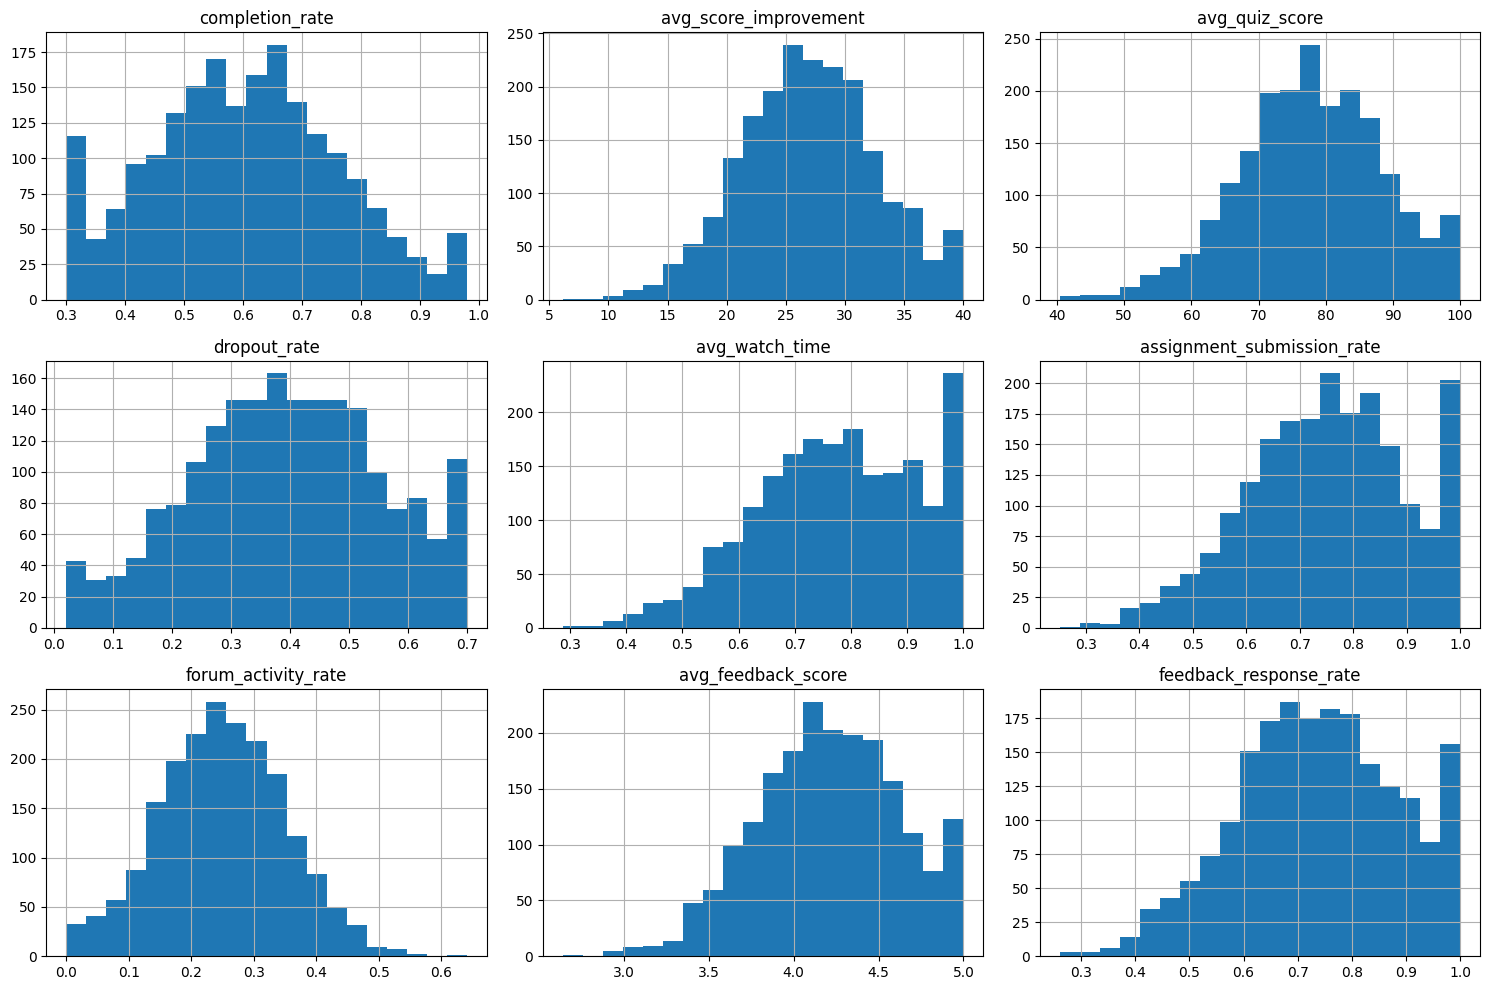

In [9]:
df.hist(figsize=(15, 10), bins=20)

plt.tight_layout()
plt.show()

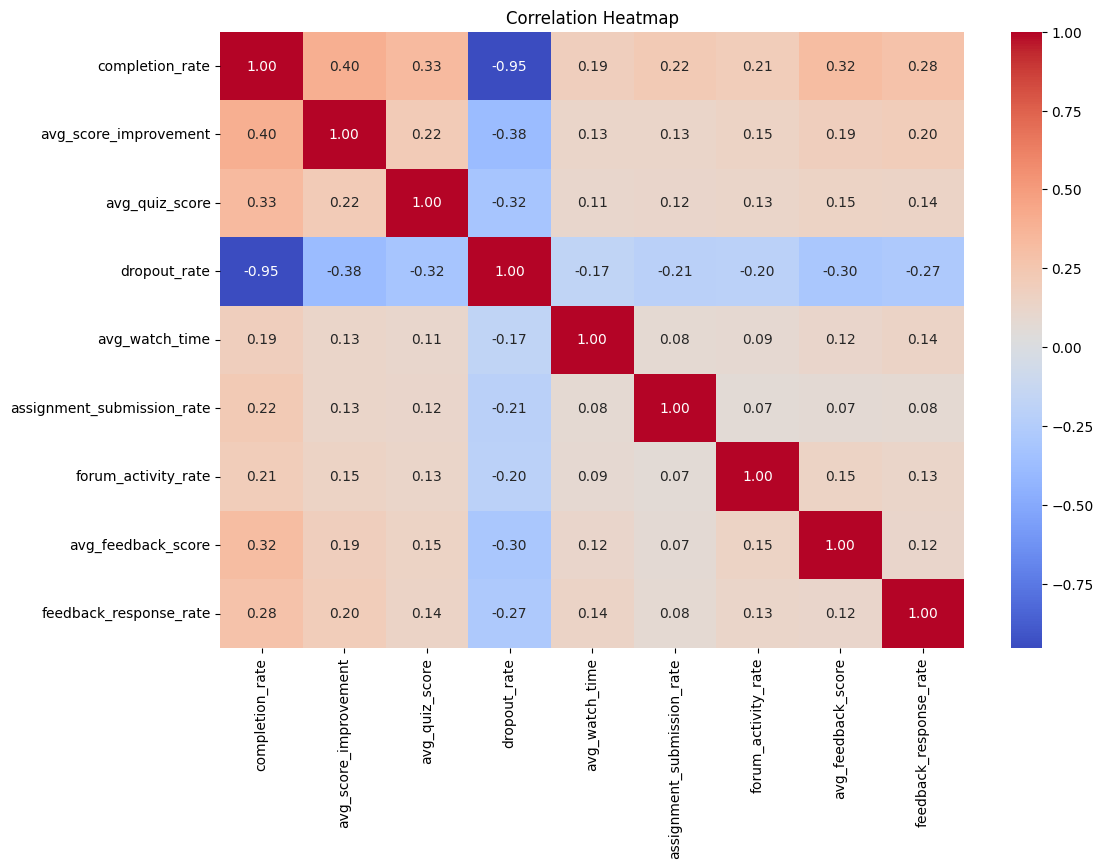

In [10]:
correlation = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

In [11]:
correlation = df.select_dtypes(include=np.number).corr()

print(correlation.round(2))

                            completion_rate  avg_score_improvement  \
completion_rate                        1.00                   0.40   
avg_score_improvement                  0.40                   1.00   
avg_quiz_score                         0.33                   0.22   
dropout_rate                          -0.95                  -0.38   
avg_watch_time                         0.19                   0.13   
assignment_submission_rate             0.22                   0.13   
forum_activity_rate                    0.21                   0.15   
avg_feedback_score                     0.32                   0.19   
feedback_response_rate                 0.28                   0.20   

                            avg_quiz_score  dropout_rate  avg_watch_time  \
completion_rate                       0.33         -0.95            0.19   
avg_score_improvement                 0.22         -0.38            0.13   
avg_quiz_score                        1.00         -0.32            0.1

Checking for outliers

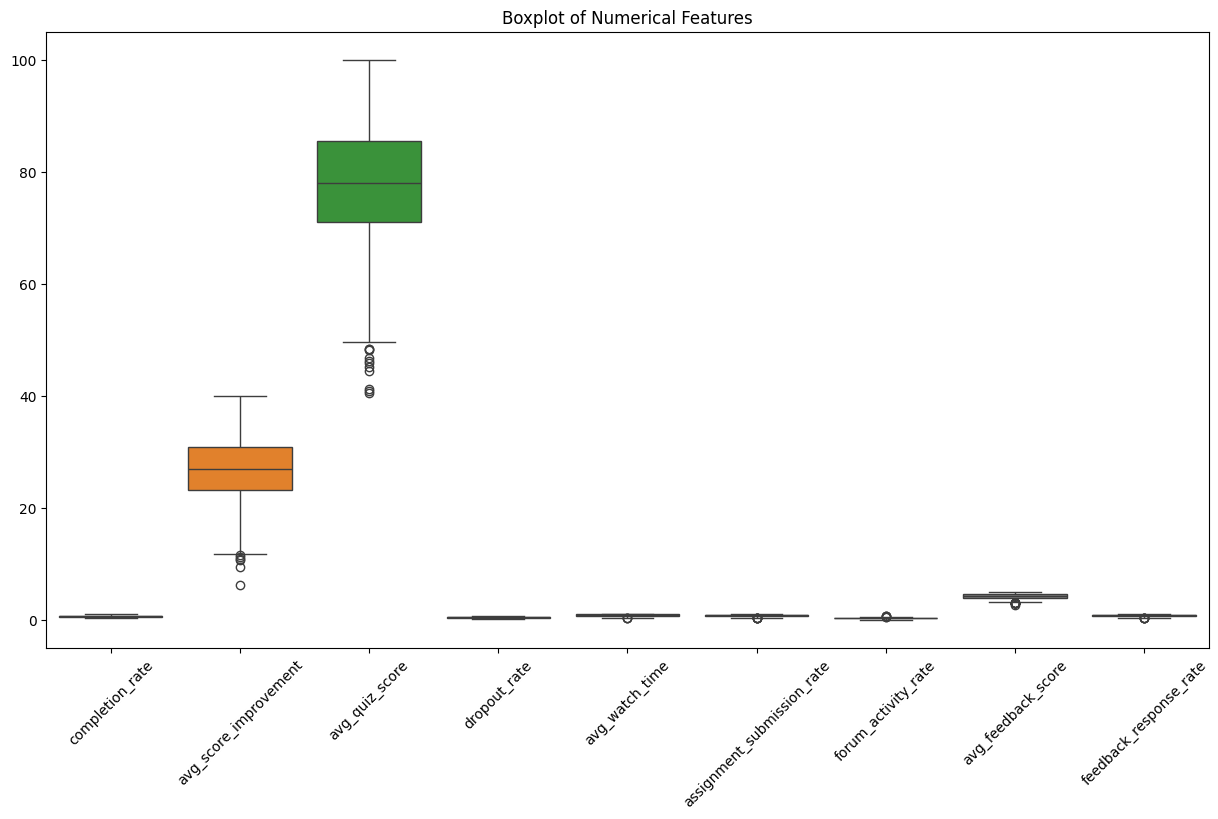

In [12]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=df.select_dtypes(include=np.number))

plt.xticks(rotation=45)
plt.title("Boxplot of Numerical Features")
plt.show()

In [13]:
numeric_df = df.select_dtypes(include=np.number)

for column in numeric_df.columns:
    Q1 = numeric_df[column].quantile(0.25)
    Q3 = numeric_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = numeric_df[
        (numeric_df[column] < lower) |
        (numeric_df[column] > upper)
    ]

    print(column, ":", len(outliers))

completion_rate : 0
avg_score_improvement : 6
avg_quiz_score : 11
dropout_rate : 0
avg_watch_time : 3
assignment_submission_rate : 6
forum_activity_rate : 5
avg_feedback_score : 11
feedback_response_rate : 5


### Outlier Analysis

The IQR method was used to identify potential outliers in numerical features. A small number of potential outliers were found in some features, while completion_rate and dropout_rate had no detected outliers. These values were not removed because they may represent genuine variations in batch performance.

## 2. Instructor Effectiveness Score

An Instructor Effectiveness Score is a numerical value used to measure an instructor's overall effectiveness based on batch performance.

In this assignment, the score is calculated using different performance indicators such as completion rate, score improvement, quiz score, dropout rate, watch time, assignment submission, forum activity, and feedback.

Higher completion rates, learning improvements, engagement, and feedback indicate better effectiveness, while higher dropout rates indicate lower effectiveness.

A weighted scoring method is used to combine these indicators into a single score. The final score is then classified into three categories: Low, Medium, and High.

Normalize the numerical features

In [14]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

numeric_columns = df.select_dtypes(include=np.number).columns

df_normalized = df.copy()

df_normalized[numeric_columns] = scaler.fit_transform(df[numeric_columns])

df_normalized.head()

,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.000000,0.238373,0.556249,0.922681,0.683637,0.720811,0.169103,0.477227,0.369235
1,B_0354,I_119,C_06,0.525324,0.493839,0.619419,0.595732,0.291198,0.998085,0.437599,1.000000,0.640690
2,B_1334,I_050,C_03,0.000000,0.293382,0.657185,1.000000,0.968987,0.742683,0.322898,0.371797,0.569542
3,B_0906,I_024,C_21,0.499274,0.534901,0.988179,0.462731,0.784601,0.391839,0.477913,0.664240,1.000000
4,B_1290,I_001,C_08,0.334267,0.736459,0.989825,0.736911,0.884150,0.820915,0.393519,0.756886,0.590184


In [15]:
df_normalized["retention_score"] = 1 - df_normalized["dropout_rate"]

df_normalized[["dropout_rate", "retention_score"]].head()

,dropout_rate,retention_score
0,0.922681,7.731867e-02
1,0.595732,4.042678e-01
2,1.000000,-2.220446e-16
3,0.462731,5.372689e-01
4,0.736911,2.630895e-01


Calculating the weighted Instructor Effectiveness Score

In [16]:
df_normalized["effectiveness_score"] = (
    df_normalized["completion_rate"] * 0.20 +
    df_normalized["avg_score_improvement"] * 0.15 +
    df_normalized["avg_quiz_score"] * 0.15 +
    df_normalized["retention_score"] * 0.15 +
    df_normalized["avg_watch_time"] * 0.10 +
    df_normalized["assignment_submission_rate"] * 0.10 +
    df_normalized["forum_activity_rate"] * 0.05 +
    df_normalized["avg_feedback_score"] * 0.05 +
    df_normalized["feedback_response_rate"] * 0.05
)

df_normalized[["instructor_id", "effectiveness_score"]].head()

,instructor_id,effectiveness_score
0,I_044,0.322014
1,I_119,0.565536
2,I_050,0.376964
3,I_024,0.633659
4,I_001,0.622795


Classify scores into Low, Medium, and High

In [17]:
def classify_effectiveness(score):
    if score < 0.40:
        return "Low"
    elif score < 0.60:
        return "Medium"
    else:
        return "High"

df_normalized["effectiveness_tier"] = (
    df_normalized["effectiveness_score"].apply(classify_effectiveness)
)

df_normalized[["instructor_id", "effectiveness_score", "effectiveness_tier"]].head()

,instructor_id,effectiveness_score,effectiveness_tier
0,I_044,0.322014,Low
1,I_119,0.565536,Medium
2,I_050,0.376964,Low
3,I_024,0.633659,High
4,I_001,0.622795,High


Checking the distribution of effectiveness tiers

effectiveness_tier
Medium    1006
High       787
Low        207
Name: count, dtype: int64


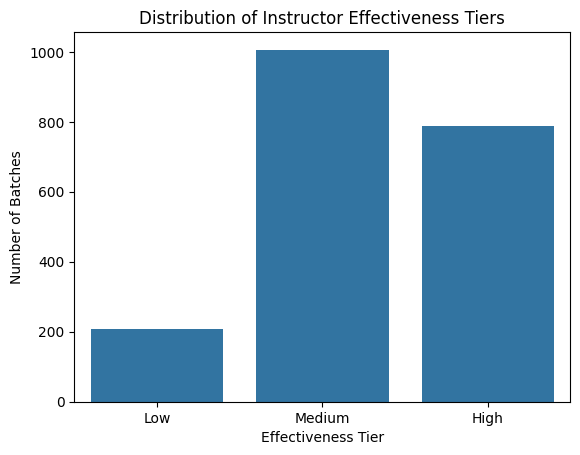

In [18]:
print(df_normalized["effectiveness_tier"].value_counts())

sns.countplot(data=df_normalized, x="effectiveness_tier")
plt.title("Distribution of Instructor Effectiveness Tiers")
plt.xlabel("Effectiveness Tier")
plt.ylabel("Number of Batches")
plt.show()

### Effectiveness Tier Distribution

The 2,000 batches were classified into three effectiveness tiers: Low, Medium, and High. The Medium category contains 1,006 batches, followed by High with 787 batches and Low with 207 batches.

The distribution shows class imbalance, as the number of Low-effectiveness batches is considerably smaller than the other categories. This will be considered during model evaluation.

Instructor-Level Aggregation

Step 1: Check the number of unique instructors

In [19]:
print("Total batches:", df_normalized.shape[0])
print("Total unique instructors:", df_normalized["instructor_id"].nunique())

Total batches: 2000
Total unique instructors: 120


Step 2: Aggregate batch-level data

In [20]:
instructor_df = df_normalized.groupby("instructor_id").agg({
    "completion_rate": "mean",
    "avg_score_improvement": "mean",
    "avg_quiz_score": "mean",
    "dropout_rate": "mean",
    "retention_score": "mean",
    "avg_watch_time": "mean",
    "assignment_submission_rate": "mean",
    "forum_activity_rate": "mean",
    "avg_feedback_score": "mean",
    "feedback_response_rate": "mean",
    "effectiveness_score": "mean",
    "batch_id": "count"
}).reset_index()

instructor_df.rename(columns={"batch_id": "total_batches"}, inplace=True)

instructor_df.head()

,instructor_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,retention_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,effectiveness_score,total_batches
0,I_001,0.358658,0.605253,0.646055,0.662637,0.337363,0.672327,0.635317,0.375209,0.668547,0.587682,0.522369,25
1,I_002,0.633639,0.709411,0.693645,0.334109,0.665891,0.771799,0.698745,0.451731,0.721621,0.708591,0.678221,20
2,I_003,0.688892,0.703843,0.691192,0.315924,0.684076,0.745203,0.705706,0.462047,0.766972,0.746147,0.693494,18
3,I_004,0.232836,0.495047,0.625592,0.775384,0.224616,0.709681,0.677277,0.352917,0.608662,0.623627,0.466312,17
4,I_005,0.823158,0.780993,0.762270,0.184902,0.815098,0.785317,0.835679,0.520220,0.662095,0.708399,0.775021,19


Step 3: Check the aggregated dataset

In [21]:
print("Instructor-level dataset shape:", instructor_df.shape)

print("\nBatch count summary:")
print(instructor_df["total_batches"].describe())

Instructor-level dataset shape: (120, 13)

Batch count summary:
count    120.000000
mean      16.666667
std        4.582270
min        7.000000
25%       13.750000
50%       17.000000
75%       19.000000
max       31.000000
Name: total_batches, dtype: float64


### Instructor-Level Aggregation

The original dataset contains 2,000 batch-level records belonging to 120 unique instructors. To obtain instructor-level data, records were grouped using instructor_id.

The mean aggregation method was used for numerical performance metrics because it represents the average performance of each instructor across their batches. The number of batches handled by each instructor was also calculated.

The aggregated dataset contains 120 instructor records. Instructors handled between 7 and 31 batches, with an average of approximately 17 batches per instructor. Since instructors have different numbers of batches, their performance estimates may have different levels of reliability.

4: Machine Learning Model

Step 1: Create instructor-level effectiveness tiers

In [22]:
instructor_df["effectiveness_tier"] = (
    instructor_df["effectiveness_score"].apply(classify_effectiveness)
)

instructor_df[[
    "instructor_id",
    "effectiveness_score",
    "effectiveness_tier",
    "total_batches"
]].head()

,instructor_id,effectiveness_score,effectiveness_tier,total_batches
0,I_001,0.522369,Medium,25
1,I_002,0.678221,High,20
2,I_003,0.693494,High,18
3,I_004,0.466312,Medium,17
4,I_005,0.775021,High,19


Step 2: Check instructor-level class distribution


effectiveness_tier
Medium    67
High      42
Low       11
Name: count, dtype: int64


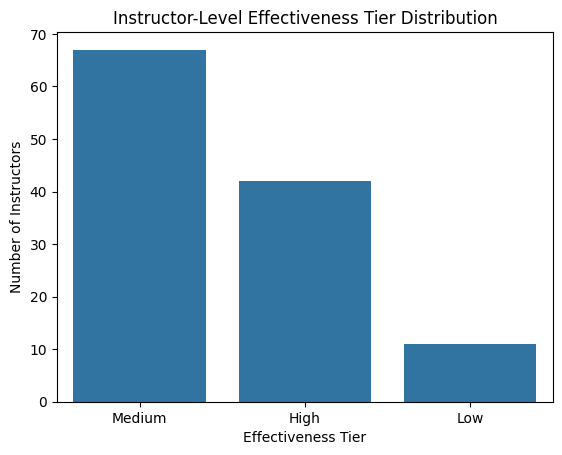

In [23]:
print(instructor_df["effectiveness_tier"].value_counts())

sns.countplot(data=instructor_df, x="effectiveness_tier")
plt.title("Instructor-Level Effectiveness Tier Distribution")
plt.xlabel("Effectiveness Tier")
plt.ylabel("Number of Instructors")
plt.show()

Step 3: Prepare input features (X) and target (y)


In [24]:
X = instructor_df.drop(columns=[
    "instructor_id",
    "effectiveness_score",
    "effectiveness_tier",
    "total_batches"
])

y = instructor_df["effectiveness_tier"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (120, 10)
Target shape: (120,)


Step 4: Split the dataset into training and testing sets


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (96, 10)
Testing data: (24, 10)


Step 5: Train a Machine Learning model


Random Forest Classifier

In [26]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [27]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Tier": y_test.values,
    "Predicted Tier": y_pred
})

results.head(10)

,Actual Tier,Predicted Tier
0,Medium,Medium
1,Medium,Medium
2,Medium,Medium
3,Low,Low
4,High,High
5,Medium,Medium
6,High,High
7,Medium,Medium
8,High,High
9,Medium,Medium


Step 7: Evaluate the model

In [28]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 0.9583

Classification Report:
              precision    recall  f1-score   support

        High       0.90      1.00      0.95         9
         Low       1.00      1.00      1.00         2
      Medium       1.00      0.92      0.96        13

    accuracy                           0.96        24
   macro avg       0.97      0.97      0.97        24
weighted avg       0.96      0.96      0.96        24



confusion matrix


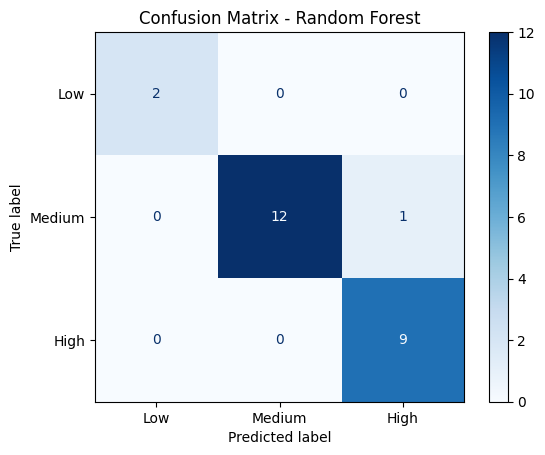

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=["Low", "Medium", "High"])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.show()

Identifying important features

                      Feature  Importance
4             retention_score    0.258819
0             completion_rate    0.217086
3                dropout_rate    0.179877
2              avg_quiz_score    0.111763
1       avg_score_improvement    0.067098
8          avg_feedback_score    0.049076
9      feedback_response_rate    0.045827
6  assignment_submission_rate    0.043148
7         forum_activity_rate    0.015580
5              avg_watch_time    0.011725


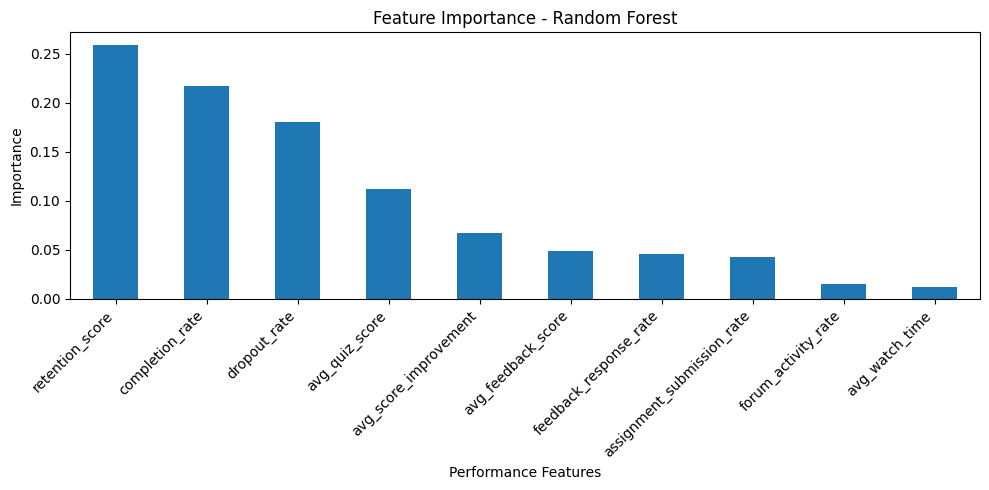

In [30]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

feature_importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Performance Features")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Feature Importance Analysis

The Random Forest model identified retention_score, completion_rate, and dropout_rate as the three most important features, with importance values of approximately 25.88%, 21.71%, and 17.99%, respectively.

This indicates that student retention and course completion play important roles in the model's predictions. Average quiz score and score improvement also contribute to the predictions.

Forum activity and average watch time have relatively low feature importance in this model.

These values represent the model's relative feature importance, not proof of causal relationships. Retention score and dropout rate are closely related, which may influence their importance values.

## 5. Final Discussion and Insights

### 1. Which features most influenced instructor effectiveness, and why?

The most influential features were retention score (25.88%), completion rate (21.71%), and dropout rate (17.99%). These features indicate how well students remain engaged and complete their courses. Average quiz score and score improvement also contributed to the model's predictions because they reflect student learning performance.

### 2. Which variables could be misleading or confounded?

Dropout rate and retention score are closely related because retention score is calculated as 1 minus dropout rate. Completion rate is also strongly negatively correlated with dropout rate. Therefore, these variables may contain overlapping information. Other factors, such as course difficulty, student background, and batch size, may also influence the performance metrics.

### 3. How could the model fail in real-world usage?

The model may produce misleading predictions if it is applied to instructors teaching different courses or student groups. It was trained on only 120 instructors, and the Low category contains very few examples. Changes in course difficulty, student participation, or learning conditions may also affect its predictions.

### 4. What additional data would improve the analysis?

Additional data such as student background, prior knowledge, course difficulty, batch size, instructor experience, teaching methods, and student feedback would improve the analysis. Data collected across multiple semesters would also help evaluate instructor performance more reliably.

### 5. Should this model be used for instructor performance evaluation? Why or why not?

The model should not be used as the sole method for evaluating instructor performance. It can be used as a supporting analytical tool to identify performance patterns and areas for improvement. Human evaluation, classroom observations, student feedback, and other contextual factors should also be considered before making decisions about instructors.